# 03 — Dummy, Logistic Regression & kNN

Phase v1/03 · Owner: Rajat Srivastav

Tune every choice on the fixed 54k/6k train/validation split. Final fits use 60k images. Test data is accessed only by `final_test_run()`.

Saved validation and test JSONs are reused on subsequent runs. This lets Restart & Run All reproduce figures and analysis without evaluating the test set again. A cached test result must match the selected validation parameters. To investigate a genuine bug requiring another test run, document the reason in decisions.md first; preserve the audit log.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src import config
from src.experiment import tune_on_val, final_test_run
from src.models_linear import make_dummy, make_logreg, make_knn, DUMMY_GRID, LOGREG_GRID, KNN_GRID
from src.utils import save_fig, set_seed

set_seed()
factories = {"dummy": make_dummy, "logreg": make_logreg}
grids = {"dummy": DUMMY_GRID, "logreg": LOGREG_GRID}
validation = {}
test_results = {}


Matplotlib is building the font cache; this may take a moment.


## Validation first

⏱ LR validation takes about 3–5 minutes on this machine when caches are missing. LR uses StandardScaler inside its Pipeline and an L2-regularised multinomial classifier. All C values are scored on validation; the highest accuracy wins, with exact ties resolved by grid order.

For class c, the model computes a score `w_c · x + b_c`, then softmax converts the ten scores into probabilities. Training minimises cross-entropy (negative log probability of the correct class) plus the weight penalty. Smaller C means stronger regularisation: it discourages large weights and can reduce overfitting. The iteration cap is 5,000 because two initial large-C pixel fits reached 1,000 iterations.

In [2]:
for name, make_fn in factories.items():
    for kind in ("pixels", "hog"):
        experiment = f"{name}_{kind}"
        path = config.METRICS_DIR / f"{experiment}_val.json"
        if not path.exists():
            tune_on_val(name, make_fn, grids[name], kind)
        result = json.loads(path.read_text())
        assert result["grid"] == grids[name]
        validation[experiment] = result
        print(experiment, result["best_params"], "val accuracy:", result["best_val_acc"])


dummy_pixels {} val accuracy: 0.1
dummy_hog {} val accuracy: 0.1
logreg_pixels {'C': 0.01} val accuracy: 0.8642
logreg_hog {'C': 0.01} val accuracy: 0.8927


saved results/figures/linear_logreg_val_curve_pixels.png


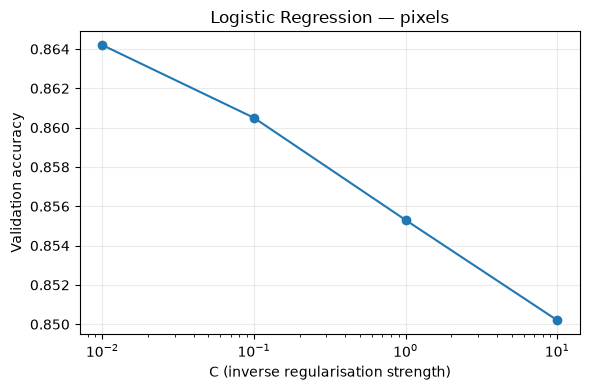

saved results/figures/linear_logreg_val_curve_hog.png


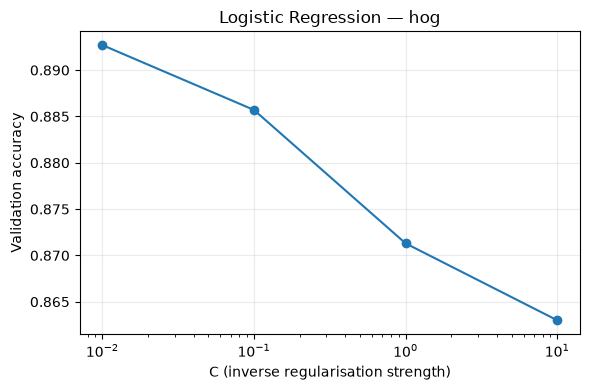

In [3]:
for kind in ("pixels", "hog"):
    result = validation[f"logreg_{kind}"]
    rows = result["rows"]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.semilogx([row["params"]["C"] for row in rows], [row["val_acc"] for row in rows], "o-")
    ax.set(xlabel="C (inverse regularisation strength)", ylabel="Validation accuracy",
           title=f"Logistic Regression — {kind}")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    save_fig(fig, f"linear_logreg_val_curve_{kind}")
    plt.show()


## Final evaluation — one recorded run per experiment

⏱ LR final fits take about 15–30 seconds per feature set. Each missing result is produced once through `final_test_run`; subsequent notebook runs read only stored metrics. Dummy predicts the most frequent training class. The balanced data makes that class 0 under sklearn's tie rule, yielding 10% accuracy for either feature set.

In [4]:
for name, make_fn in factories.items():
    for kind in ("pixels", "hog"):
        experiment = f"{name}_{kind}"
        params = validation[experiment]["best_params"]
        path = config.METRICS_DIR / f"{experiment}_test.json"
        if path.exists():
            result = json.loads(path.read_text())
            if result["best_params"] != params:
                raise RuntimeError(f"{experiment}: saved test parameters differ; investigate and log any rerun first.")
        else:
            result = final_test_run(name, make_fn, params, kind)
        test_results[experiment] = result
display(pd.DataFrame([{"experiment": key, "params": value["best_params"],
                      "val_acc": validation[key]["best_val_acc"], "test_acc": value["accuracy"],
                      "macro_f1": value["macro_f1"], "fit_s": value["train_time_s"],
                      "inference_ms_per_1000": value["inference_ms_per_1000"]}
                     for key, value in test_results.items()]))


final fit logreg_pixels on 60000 images: 30.4s


saved results/metrics/logreg_pixels_test.json
logreg_pixels: test accuracy 0.8472 | macro F1 0.8464


final fit logreg_hog on 60000 images: 45.8s


saved results/metrics/logreg_hog_test.json
logreg_hog: test accuracy 0.8886 | macro F1 0.8885


,experiment,params,val_acc,test_acc,macro_f1,fit_s,inference_ms_per_1000
0,dummy_pixels,{},0.1000,0.1000,0.0182,0.00,0.00
1,dummy_hog,{},0.1000,0.1000,0.0182,0.16,0.01
2,logreg_pixels,{'C': 0.01},0.8642,0.8472,0.8464,30.38,1.05
3,logreg_hog,{'C': 0.01},0.8927,0.8886,0.8885,45.76,2.29
